# Cluster B · Evaluating long-term episodic memory
**Research seminar · Integrated computational notebook**

## 1. Research context
The overarching question is **which LLM memory architectures are most promising for reducing hallucinations?** RQ1 describes evaluation rubrics and failure modes. RQ2 describes mechanisms. RQ3 asks how architectures compare at mitigating specific failures across benchmarks. This notebook addresses RQ3 for **Cluster B**, long-term episodic memory, including supplementary evidence for closely related tasks.

An episodic-memory system stores or reconstructs context from previous interactions. It must selectively write memories, retrieve them and reconcile updates before the reader uses them. The corpus includes retrieval pipelines, dedicated memory stores, consolidation and reflection, and selective-answering interventions. A named family, an implementation and an evaluated configuration are distinct objects. A gate added to Mem0 does not identify a gate effect in every memory framework. Source taxonomy and candidate decisions are documented in the repository's RQ2 taxonomy and the Stage 2E report.

**How to read this notebook.** Run top to bottom in Python 3.12. It reads the saved Stage 1E tables, reruns the existing Stage 2 modules in a temporary copy and tests the regenerated results against the saved ones. The notebook uses local scientific packages and requires no network or source PDFs for execution. Figure captions identify the original scopes. The last cell removes the temporary run.

In [1]:
import csv
from collections import Counter
from decimal import Decimal
from html import escape
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys
from tempfile import TemporaryDirectory

from IPython.display import HTML, Image, display

def find_project(start):
    for folder in (start, *start.parents):
        for candidate in (folder, folder / "cluster_b_analysis"):
            if (candidate / "data/validated_results.csv").is_file() and (candidate / "src/effect_sizes.py").is_file():
                return candidate
    raise FileNotFoundError("Start the kernel from the repository, cluster_b_analysis, or its notebooks directory.")

project = find_project(Path.cwd())
sys.path.insert(0, str(project.parent))
from cluster_b_analysis.src.data_loading import load_matched_pairs, read_score
from cluster_b_analysis.src.effect_sizes import effect_row, rmm_example
from cluster_b_analysis.src.sensitivity import TOLERANCES, load_panels, tolerance_edges

def read(path):
    with path.open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle))

def table(headers, rows):
    def tr(items, tag):
        return "<tr>" + "".join(f"<{tag}>{escape(str(item))}</{tag}>" for item in items) + "</tr>"
    display(HTML("<table><thead>" + tr(headers, "th") + "</thead><tbody>" +
                 "".join(tr(row, "td") for row in rows) + "</tbody></table>"))

def fields(rows, *keys):
    table(keys, ([row[key] for key in keys] for row in rows))

def figure(path, caption):
    display(Image(filename=str(path), embed=True))
    display(HTML(f"<p><em>{escape(caption)}</em></p>"))

data = project / "data"
saved = project / "results"
observations = read(data / "validated_results.csv")
by_id = {row["observation_id"]: row for row in observations}
raw = read(data / "raw_results.csv")

## 2. Experimental database
The 24 selected publications were screened before detailed extraction. Experimental panels were selected for relevance to episodic memory, common scoring conditions, control arms and diagnostic outcomes. The PDF index guided targeted inspection. Published values were transcribed and checked at their exact table, row, column and physical page. Stage 1E retains reported uncertainty, distinct system settings, judges, and source-specific limitations. See the extraction status, discrepancy log and data dictionary in `data/`.

A verified cell establishes what a source reports. A printed score can still be imported from an earlier publication, duplicate an observation or face an unresolved interpretation. These cells remain available for provenance with eligibility exclusions. Blank fields represent unavailable or inapplicable quantities. A digitized plot estimate is distinct from a verified printed result, and an unavailable value carries no score. Examples include duplicate baselines, unresolved MemBook row attribution and MRAgent F1 discrepancies.

In [2]:
status = read(data / "extraction_status.csv")
retained = [r for r in observations if r["provenance"] == "original" and r["synthesis_exclude"] == "no"]
corpus = {
    "Publications assessed": sum(r["detailed_extraction_completed"] == "yes" for r in status),
    "Raw source records": len(raw),
    "Verified numerical observations": len(observations),
    "Retained original observations": len(retained),
    "Source configuration IDs": len({r["configuration_id"] for r in observations}),
}
table(("Corpus statistic", "Count"), corpus.items())
assert (len(status), corpus["Publications assessed"], len(observations), len(retained)) == (24, 24, 4319, 3168)

Corpus statistic,Count
Publications assessed,24
Raw source records,4948
Verified numerical observations,4319
Retained original observations,3168
Source configuration IDs,1126


## 3. Experimental comparability
A **protocol block** specifies the relevant study, workload, outcome, tested configurations and scoring regime. A **dependence cohort** groups blocks that may share questions, source histories, generated answers or runs. Cohort labels are conservative bookkeeping, so distinct labels do not automatically establish statistical independence.

Strict evidence uses original verified, non-excluded observations with directly comparable within-block conditions. Relaxed coverage also admits conditional same-study comparisons, whose documented differences may involve backbones, scorers, task definitions or budgets. Imported controls and incompatible cross-study comparisons do not become edges by sharing architecture names. A graph edge projects a particular comparison onto named systems. A path can pass through one name implemented with different settings, and connectivity is therefore weaker than measurement compatibility. Components are graph summaries, with isolated systems included in their counts.

Known cross-protocol dependence includes IMLogic: its new questions reuse the original HaluMem-Medium user dialogue histories, and HaluMem-Long extends those users. Separate IMLogic and HaluMem cohort labels therefore describe different protocols, with shared history lineage. SIRIN reuses LongMemEval questions, and BioMem evaluates a medical subset of RealMem. The 28 recorded cohort labels do not count disjoint samples.

Projection,Labels,Edges,Components,Largest component
strict,63,191,16,36
relaxed,63,315,4,50


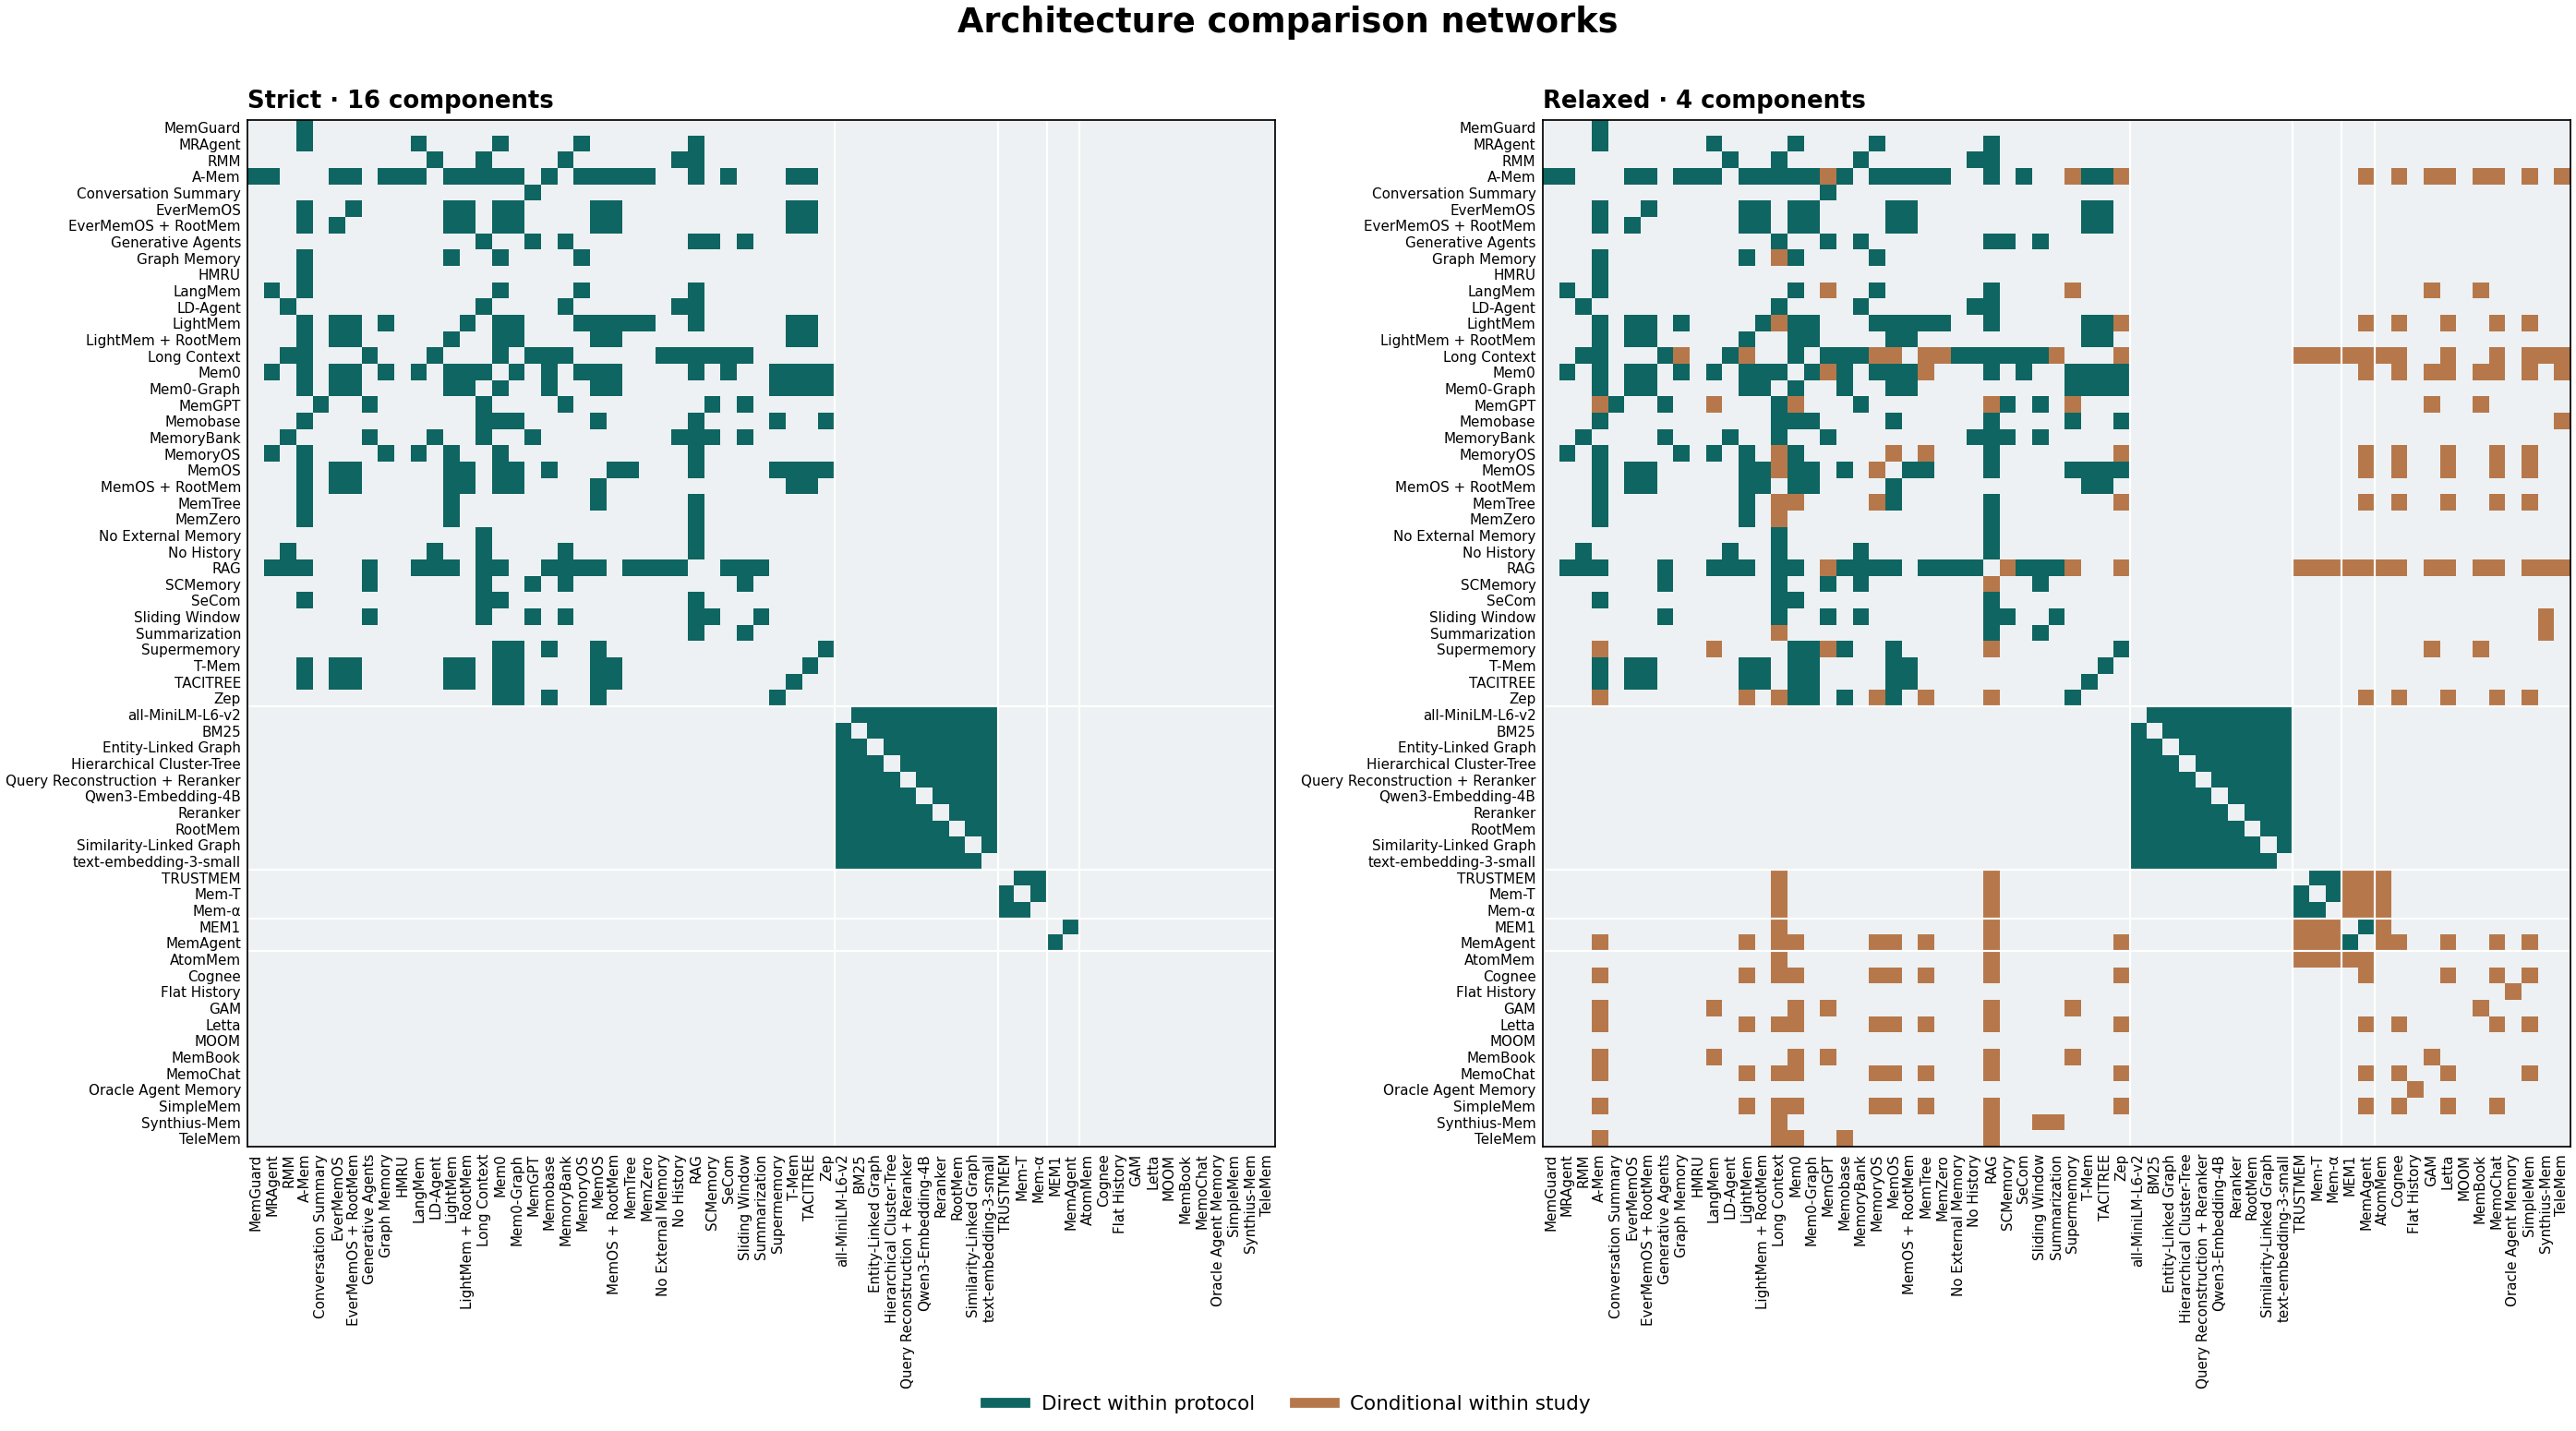

In [3]:
edges = read(data / "comparison_graph_edges.csv")
components = read(data / "comparison_graph_components.csv")
summary = []
for mode in ("strict", "relaxed"):
    nodes = [r for r in components if r["graph"] == mode]
    links = {(r["architecture_a"], r["architecture_b"]) for r in edges
             if mode == "relaxed" or r["status"] == "Directly comparable"}
    sizes = Counter(r["component"] for r in nodes)
    summary.append((mode, len(nodes), len(links), len(sizes), max(sizes.values())))
table(("Projection", "Labels", "Edges", "Components", "Largest component"), summary)
figure(project / "figures/comparison_network.png",
       "Stage 1E architecture network. Edges summarize eligible or qualified source-local pairs. Labels can conceal distinct settings, and paths supply no independent replication.")

### Reproduce the Stage 2 pipeline
The Stage 1E tables and graph are provenance-sensitive outputs, built by the existing database and coverage utilities from the saved source transcriptions. A full Stage 1 rebuild also validates source locators against local PDFs. Here we reuse the reviewed database and graph as inputs. Stages 2A–2E execute sequentially with their existing entry points. Stage 2D uses its fixed seed of 27 where it samples objective weights.

In [4]:
scratch = TemporaryDirectory(prefix="cluster-b-notebook-")
run_dir = Path(scratch.name)
analysis = run_dir / "cluster_b_analysis"
analysis.mkdir()
shutil.copytree(project / "src", analysis / "src", ignore=shutil.ignore_patterns("__pycache__"))
shutil.copytree(data, analysis / "data")
for folder in ("results", "figures"):
    (analysis / folder).mkdir()
env = dict(os.environ, PYTHONHASHSEED="0", MPLBACKEND="Agg",
           MPLCONFIGDIR=str(run_dir / "matplotlib"), XDG_CACHE_HOME=str(run_dir / "cache"))
result, figures = analysis / "results", analysis / "figures"
modules = ("effect_sizes", "failure_mode_analysis", "stage2c_analysis", "sensitivity", "candidate_selection")
for module in modules:
    completed = subprocess.run([sys.executable, "-B", "-m", f"cluster_b_analysis.src.{module}"],
                               cwd=run_dir, env=env, capture_output=True, text=True)
    if completed.returncode:
        raise RuntimeError(f"{module} failed: " + completed.stdout + completed.stderr)
    print(completed.stdout.strip())

def csv_signature(path):
    with path.open(encoding="utf-8", newline="") as handle:
        rows = csv.reader(handle)
        return next(rows), Counter(map(tuple, rows))

checks = sorted(result.glob("*.csv")) + [analysis / "data/architecture_registry.csv"]
stage2_tables = (
    "architecture_evidence_profiles",
    "architecture_failure_mode_profiles",
    "benchmark_performance_profiles",
    "candidate_shortlist",
    "cohort_level_summary",
    "dominance_relations",
    "effect_size_sensitivity",
    "evidence_selection_sensitivity",
    "failure_mode_evidence_coverage",
    "failure_mode_tradeoffs",
    "final_failure_mode_matrix",
    "head_to_head_benchmark_comparisons",
    "matched_effect_sizes",
    "objective_selection_sensitivity",
    "objective_weight_sensitivity",
    "pareto_eligibility",
    "pareto_fronts",
    "pareto_reported_uncertainty",
    "protocol_level_summary",
    "robust_findings",
    "sirin_denominator_sensitivity",
    "stage2b_source_contrasts",
    "tolerance_sensitivity",
    "weighting_comparison",
    "within_panel_rankings",
)
expected = {f"{name}.csv" for name in stage2_tables}
assert {p.name for p in result.glob("*.csv")} == expected
for regenerated in checks:
    reference = (saved if regenerated.parent == result else data) / regenerated.name
    assert csv_signature(regenerated) == csv_signature(reference), regenerated.name
print(f"Reproduced {len(checks)} CSV schemas and row multisets exactly.")

4370 eligible contrasts; 713 baseline-relative; 3657 pairwise; 28 cohort groups.


Locality-free compatibility audit: {'candidate_scopes': 713, 'multicontrast_scopes': 0, 'cross_cohort_scopes': 0, 'cross_study_scopes': 0}
1605 selected contrasts, 1605 benchmark profiles, 1374 failure-mode profiles, 3956 coverage entries.


9 panels, 46 vectors, 131 within-panel pairs, 198 objective reversals, 8 source intervals


655 tolerance comparisons, 24 objective omissions, 46 preference rows, 798 transformation checks, 14 SIRIN products


1138 configuration records; 4370 matched contrasts; 10014 matrix entries; 16 reviewed decisions; 252 head-to-head rows.


Reproduced 26 CSV schemas and row multisets exactly.


## 4. Matched effect-size analysis
For target score $t$ and reference score $b$, set $s=+1$ for a benefit and $s=-1$ for a cost or event rate. The **direction-adjusted difference** is $\Delta=s(t-b)$, so positive favors the target. For proportions the **percentage-point difference** is $100\Delta$. For scores already expressed in percent it is $\Delta$ in points.

For ratio-scale scores with $b>0$, **relative performance improvement** is $100\Delta/b\%$. For correctness probabilities, the error complement is $e=1-p$. **Relative error reduction** for $b<1$ is
$$
100\frac{(1-b)-(1-t)}{1-b}=100\frac{t-b}{1-b}\%.
$$
For directly measured undesirable event probabilities, **relative event reduction** is $100(b-t)/b\%$ if $b>0$. The correctness complement is broader than hallucination. Relative measures require an explicit baseline and a meaningful scale or denominator. The pipeline leaves missing or undefined measures blank. A non-baseline pair retains its source orientation and absolute difference.



The strict synthesis excludes comparisons with repeated source anchors, even when the source ablation is protocol-compatible. This applies to 44 RMM and MemBook rows. A shared canonical reference would require explicit aliasing and dependence bookkeeping.

4370 contrasts; 713 baseline-relative; 140 protocol blocks; 28 potentially dependent cohorts.


Quantity,Value
reference_score,63.6000
target_score,70.4000
absolute_difference,6.8000
difference_pp,6.8000
relative_performance_improvement_pct,10.6918
relative_error_reduction_pct,18.6813
relative_undesirable_event_reduction_pct,Undefined or not applicable


Quantity,Value
reference_score,35.1000
target_score,23.2000
absolute_difference,11.9000
difference_pp,11.9000
relative_performance_improvement_pct,Undefined or not applicable
relative_error_reduction_pct,Undefined or not applicable
relative_undesirable_event_reduction_pct,33.9031


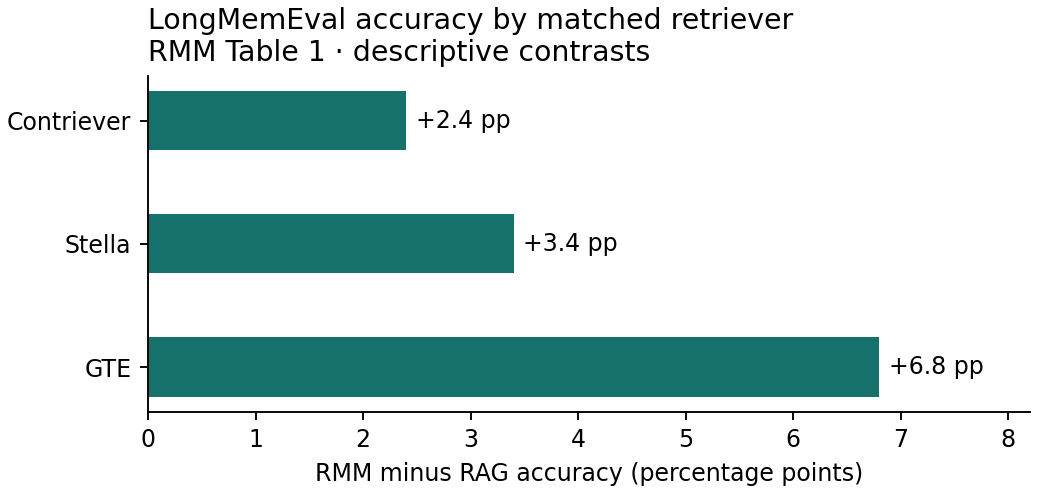

In [5]:
effects = read(result / "matched_effect_sizes.csv")
baseline = [r for r in effects if r["contrast_kind"] == "baseline_relative"]
print(len(effects), "contrasts;", len(baseline), "baseline-relative;",
      len({(r["paper_id"], r["benchmark"], r["protocol_block"]) for r in effects}), "protocol blocks;",
      len({r["cohort"] for r in effects}), "potentially dependent cohorts.")
assert (len(effects), len(baseline)) == (4370, 713)
rmm_example([effect_row(pair) for pair in load_matched_pairs(data)])
gte = next(r for r in effects if r["paper_id"] == "rmm" and r["table_id"] == "Table 1"
           and r["metric"] == "Accuracy" and r["reference_source_row"] == "RAG | GTE"
           and r["target_source_row"] == "RMM (Ours) | GTE")
gate = next(r for r in baseline if r["paper_id"] == "sirin" and r["table_id"] == "Table 8"
            and r["metric"] == "Strict unfaithfulness" and r["target_architecture"] == "Mem0"
            and "SIRIN Judge | + Faithfulness gate" in r["target_source_row"])
for row in (gte, gate):
    table(("Quantity", "Value"), ((field, round(read_score(row[field]), 4) if row[field] else "Undefined or not applicable")
                                  for field in ("reference_score", "target_score", "absolute_difference", "difference_pp",
                                                "relative_performance_improvement_pct", "relative_error_reduction_pct",
                                                "relative_undesirable_event_reduction_pct")))
figure(figures / "matched_effect_sizes_example.png",
       "RMM Table 1 LongMemEval QA, paired to RAG by retriever. GTE gives +6.8 points (70.4% vs 63.6%). Judge-error reduction is about 18.68%. Repeated-run dispersion is unavailable.")

The SIRIN example gives an 11.9-point reduction from 35.1% to 23.2%, or approximately 33.9% relative to ungated Mem0. These percentages describe different sets of served answers. Coverage simultaneously falls from 100% to 80%, and the relative event calculation establishes no all-query effect.

## 5. Cohort-balanced aggregation
Arithmetic averaging answers a question about the unit being weighted. Extra rows can reflect additional endpoints or variants from the same experiment. Within one compatible stratum, let $d_{cpe}$ be the contrast for distinct endpoint $e$ in protocol $p$ and cohort $c$. The protocol mean is $m_{cp}=n_{cp}^{-1}\sum_e d_{cpe}$. If $P_c$ is the number of protocols in cohort $c$ and $C$ is the number of cohorts, then
$$
\begin{aligned}
\bar d_{\mathrm{rows}} &= \frac{\sum_{c,p}n_{cp}m_{cp}}{\sum_{c,p}n_{cp}},\\
\bar d_{\mathrm{protocol}} &= \frac{\sum_{c,p}m_{cp}}{\sum_c P_c},\\
\bar d_{\mathrm{cohort}} &= \frac{1}{C}\sum_c\frac{1}{P_c}\sum_{p=1}^{P_c}m_{cp}.
\end{aligned}
$$

Study balance averages protocol means within each paper and then gives papers equal weight. A common estimand requires compatible workload, scorer, outcome, reference configuration and scale. The pipeline uses exact strata and checks for shared pairs or conflicting duplicates. Equal weighting changes the descriptive estimand, while correlation and confounding can remain.

When a stratum has one protocol and one cohort, each estimator reduces to its protocol mean. In this dataset the exact strata are even narrower, typically containing one retained endpoint. Agreement of weights signals absent pooling leverage. It does not imply equal architectural performance.

In [6]:
weights = read(result / "weighting_comparison.csv")
print("Profile support (endpoints, protocols, cohorts):",
      Counter((r["n_observations"], r["n_protocols"], r["n_cohorts"]) for r in weights))
weight_fields = ("observation_weighted_mean", "protocol_weighted_mean", "study_balanced_mean", "cohort_balanced_mean")
same = sum(len({Decimal(r[key]) for key in weight_fields}) == 1 for r in weights)
print(f"Exact weighting agreement: {same} / {len(weights)} profiles")
assert same == len(weights)
fields([r for r in weights if r["target_architecture"] == "RMM" and r["reference_architecture"] == "RAG"
        and r["benchmark"] == "LongMemEval" and r["metric"] == "Accuracy"][:4],
       "benchmark", "metric", "effect_unit", *weight_fields)

Profile support (endpoints, protocols, cohorts): Counter({('1', '1', '1'): 1605})
Exact weighting agreement: 1605 / 1605 profiles


benchmark,metric,effect_unit,observation_weighted_mean,protocol_weighted_mean,study_balanced_mean,cohort_balanced_mean
LongMemEval,Accuracy,percentage points,20.0,20.0,20.0,20.0
LongMemEval,Accuracy,percentage points,32.0,32.0,32.0,32.0
LongMemEval,Accuracy,percentage points,6.0,6.0,6.0,6.0
LongMemEval,Accuracy,percentage points,-0.2,-0.2,-0.2,-0.2


## 6. Failure-mode-specific performance
A failure-mode profile compares a configuration to an explicitly named reference within one protocol, endpoint and effect scale. The final inventory distinguishes direct hallucination rubrics, direct unfaithfulness, narrow task diagnostics such as false-premise rejection or retrieval of temporal evidence, and broader performance proxies. HaluMem's direct QA category includes both incorrect and fabricated answers. TRUSTMEM measures unsupported writes per transition. The two quantities refer to different stages and denominators. SIRIN's strict unfaithfulness is measured among answers that pass the gate.

Read the numerical effect beside its comparison target and evidence count. A missing class or unavailable source value carries no effect. A conditional or incompatible comparison may provide useful context without supporting a matched estimate. The structured final matrix retains provenance and scope through source IDs.

1374 quantitative failure-mode profiles


Matrix evidence status,Entries
matched,4370
published outside matching,1105
excluded or imported,1151
no verified observation,3288
source value unavailable,100


Measurement class of matched rows,Entries
specific failure-mode diagnostic,2532
general memory-performance proxy,1464
ancillary outcome,303
direct unfaithfulness,42
direct hallucination,29


task,metric,target_source_row,reference_source_row,cohort_balanced_mean,effect_unit,n_cohorts
Dynamic updating,Memory Recall,Qwen3-30B-A3B-Instruct-2507 | MemZero,Qwen3-30B-A3B-Instruct-2507 | A-MEM,-46.8,percentage points,1
Dynamic updating,QA Score,Qwen3-30B-A3B-Instruct-2507 | NaiveRAG,Qwen3-30B-A3B-Instruct-2507 | A-MEM,-4.0,percentage points,1
Temporal reasoning,QA Score,Qwen3-8B | MemZero,Qwen3-8B | A-MEM,0.0,percentage points,1
Dynamic updating,QA Score,Meditron3-Qwen2.5-14B | MemZero,Meditron3-Qwen2.5-14B | A-MEM,11.1,percentage points,1
Temporal reasoning,Memory Recall,HMRU-T,Base Method,12.5,percentage points,1
Temporal reasoning,QA Score,Meditron3-Qwen2.5-14B | MemZero,Meditron3-Qwen2.5-14B | A-MEM,-41.7,percentage points,1
Temporal reasoning,Memory Recall,Meditron3-Qwen2.5-14B | LightMem,Meditron3-Qwen2.5-14B | A-MEM,0.0,percentage points,1
Dynamic updating,QA Score,HMRU-T,Base Method,-12.12,percentage points,1
Temporal reasoning,Memory Recall,Qwen3-30B-A3B-Instruct-2507 | NaiveRAG,Qwen3-30B-A3B-Instruct-2507 | A-MEM,-12.5,percentage points,1
Temporal reasoning,Memory Recall,Qwen3-30B-A3B-Instruct-2507 | LightMem,Qwen3-30B-A3B-Instruct-2507 | A-MEM,4.2,percentage points,1


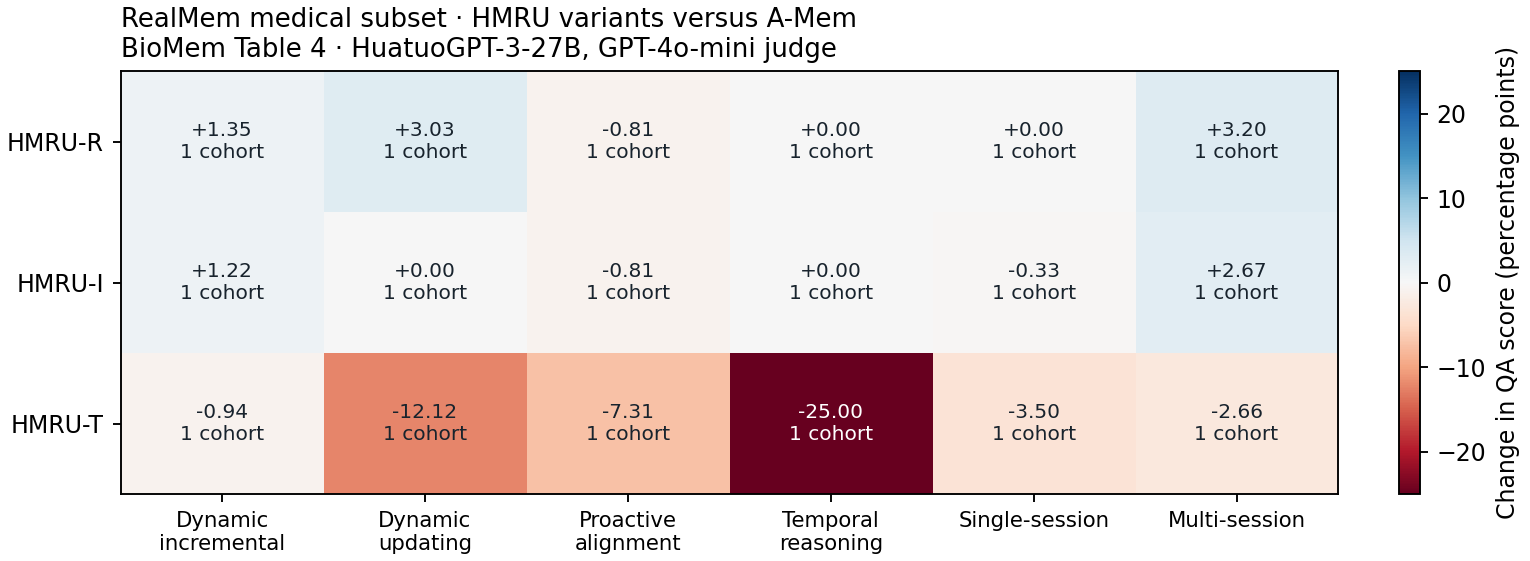

In [7]:
profiles = read(result / "architecture_failure_mode_profiles.csv")
matrix = read(result / "final_failure_mode_matrix.csv")
print(f"{len(profiles)} quantitative failure-mode profiles")
table(("Matrix evidence status", "Entries"), Counter(row["status"] for row in matrix).items())
table(("Measurement class of matched rows", "Entries"),
      Counter(row["evidence_class"] for row in matrix if row["status"] == "matched").items())
examples = [r for r in profiles if r["paper_id"] == "biomem" and r["task"] in
            {"Dynamic updating", "Temporal reasoning"} and r["reference_architecture"] == "A-Mem"]
fields(examples[:12], "task", "metric", "target_source_row", "reference_source_row",
       "cohort_balanced_mean", "effect_unit", "n_cohorts")
figure(figures / "stage2b_failure_mode_heatmap.png",
       "A compatible slice of the failure-mode profiles. Values are local to named comparators and rubrics. Blank values do not denote zero effect.")

## 7. Pareto analysis and within-panel rankings
For $k$ objectives let $z_j(x)=s_jx_j$ orient each outcome so that larger is better. Configuration $A$ **Pareto-dominates** $B$ when
$$
\big[\forall j,\ z_j(A)\ge z_j(B)\big]\ \land\
\big[\exists j,\ z_j(A)>z_j(B)\big].
$$
If differences have opposite signs across objectives, the choice entails a trade-off. The first front contains all non-dominated configurations. Later fronts remove earlier ones and apply the same rule. Per-objective competition rank is $1+\#\{B:z_j(B)>z_j(A)\}$, with equal scores tied. Strictly increasing transformations of oriented objectives preserve these point comparisons. Adding or removing an objective can change the front.

Only jointly compatible, complete vectors enter each reviewed panel. The observed order describes the reported point estimates. The methods do not identify the joint sampling distribution or establish statistical dominance. On BioMem, updating and temporal QA are evaluated under one frozen reader, while HaluMem accuracy, omission and hallucination are closely related within each split.

Panel,Configurations,First front
memgpt-msc-dmr-gpt-3-5-turbo,2,GPT-3.5 Turbo / + MemGPT
memgpt-msc-dmr-gpt-4,2,GPT-4 / + MemGPT
memgpt-msc-dmr-gpt-4-turbo,2,GPT-4 Turbo / + MemGPT
imlogic-conversation,11,"EverMemOS | + RootMem, LightMem | + RootMem, Mem0, Mem0G, MemOS | + RootMem, T-Mem, TACITREE"
biomem-medical,4,HMRU-R
sirin-mem0,7,"Mem0 | SIRIN Judge | + Both gates, Mem0 | SIRIN Judge | + Faithfulness gate, Mem0 | SIRIN Probing | + Answerability gate, Mem0 | SIRIN Probing | + Both gates, Mem0 | – | Memory baseline"
sirin-lightmem,7,"LightMem | SIRIN Judge | + Answerability gate, LightMem | SIRIN Judge | + Both gates, LightMem | SIRIN Judge | + Faithfulness gate, LightMem | – | Memory baseline"
halumem-medium,6,Medium | MemOS
halumem-long,5,Long | MemOS


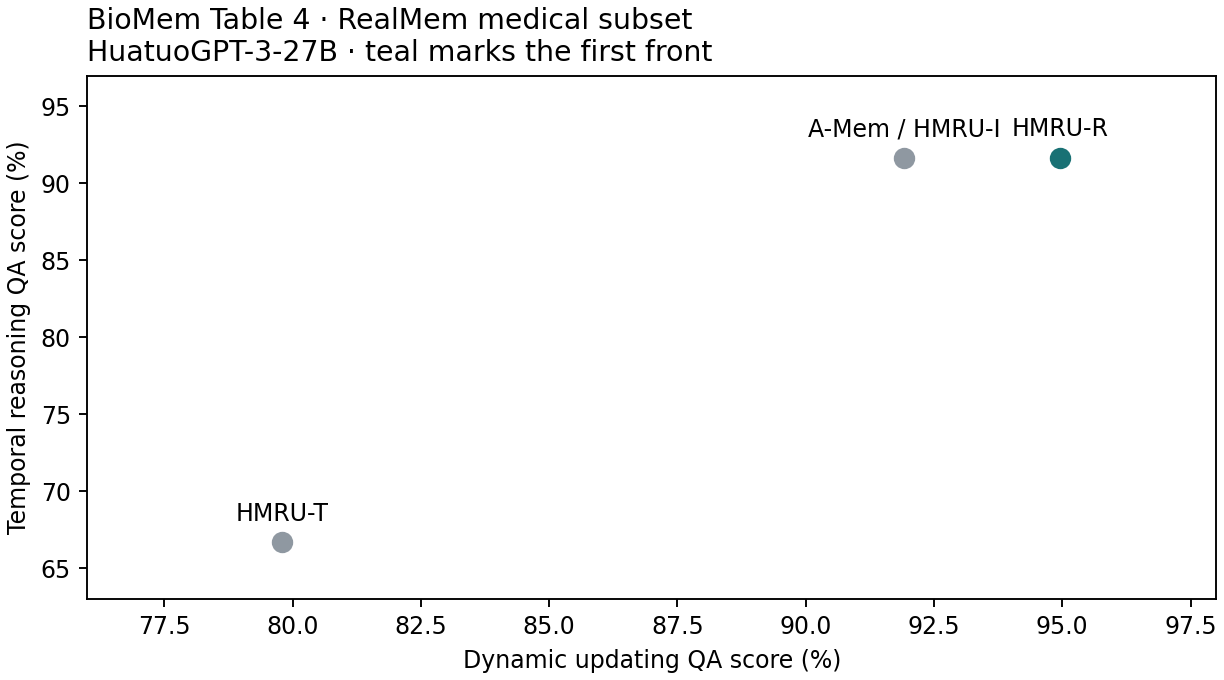

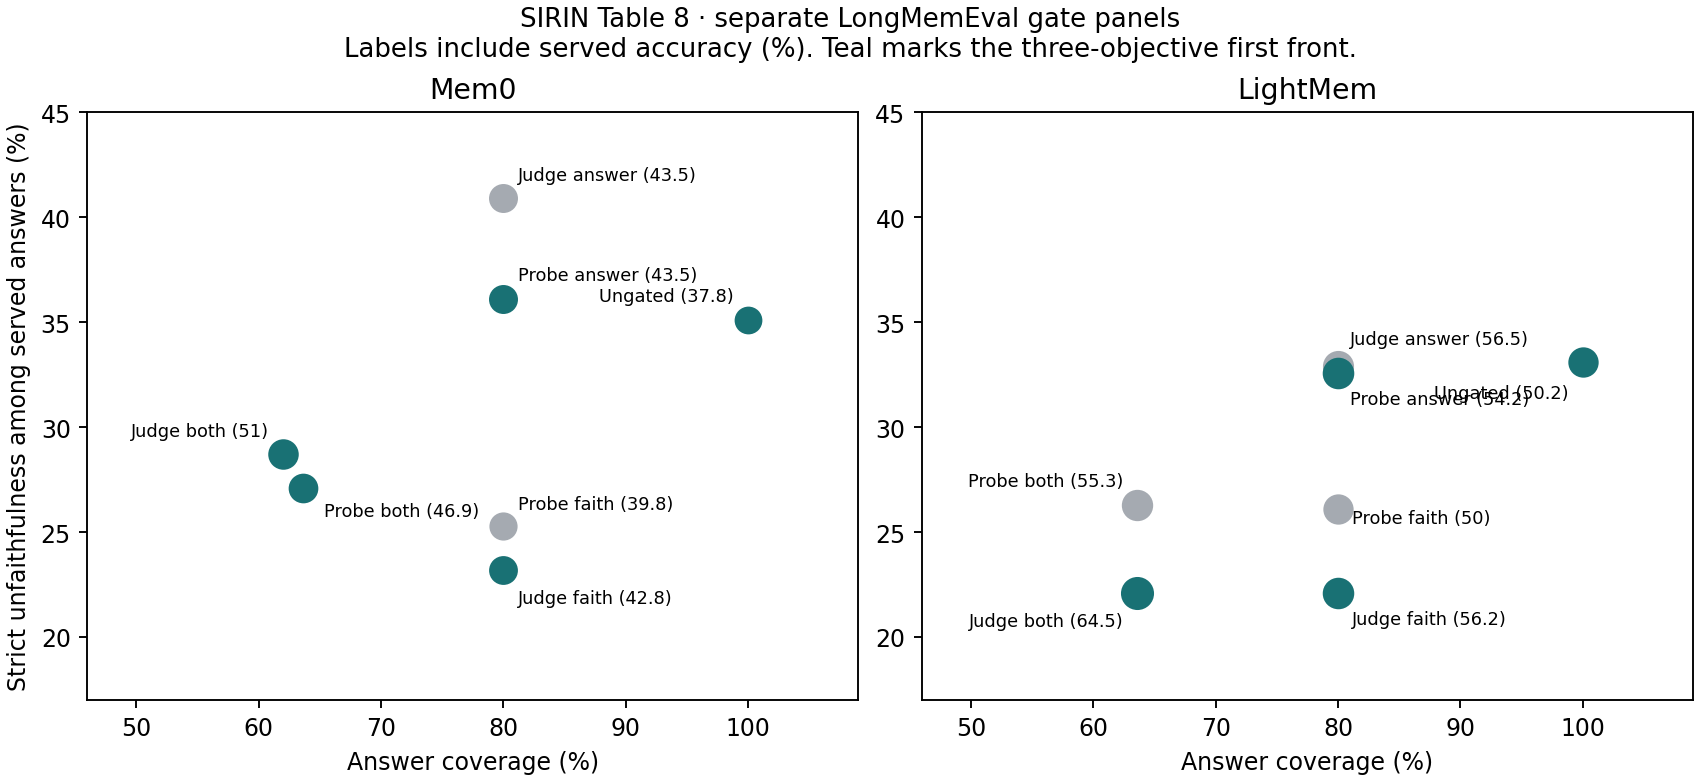

In [8]:
fronts = read(result / "pareto_fronts.csv")
table(("Panel", "Configurations", "First front"),
      ((panel, sum(r["panel"] == panel for r in fronts),
        ", ".join(r["system"] for r in fronts if r["panel"] == panel and r["front"] == "1"))
       for panel in dict.fromkeys(r["panel"] for r in fronts)))
figure(figures / "stage2c_biomem_pareto.png",
       "BioMem Table 4, RealMem medical subset. HuatuoGPT-3-27B with a fixed judge. HMRU-R leads the two selected QA objectives, with reported temporal QA tied with the base.")
figure(figures / "stage2c_sirin_coverage.png",
       "SIRIN Table 8. Coverage and strict unfaithfulness among served answers, with served accuracy annotated. Panels share questions, while the gate changes who is served.")

## 8. Sensitivity and robustness
For an oriented difference $d_j=z_j(A)-z_j(B)$, call an objective a win if $d_j>\tau_j$, a loss if $d_j<-\tau_j$, and otherwise a tie. **Tolerance-aware dominance** requires at least one win and no losses. With zero tolerance, this is Pareto dominance. Tolerated losses can accumulate, so the relation need not be transitive. In a **synthetic example** with $\tau=1$, let $A=(0,4)$, $B=(1,2)$ and $C=(2,0)$, maximizing both objectives. $A$ dominates $B$ and $B$ dominates $C$, while $A$'s first-objective loss against $C$ exceeds the tolerance. Cycles are also possible. The grid of 0, 0.5, 1, 2 and 5 points is an exploratory choice without a sampling-based equivalence interpretation.

One-objective omission measures how front membership depends on the endpoint set. For natural bounded objectives, weighted utility is $U=\sum_j w_j u_j$, with $w_j\ge0$, $\sum_j w_j=1$, and $u_j=x_j/100$ for a benefit or $u_j=1-x_j/100$ for a cost after expressing each score $x_j$ on its original bounded percentage scale. Analytical two-objective regions and seeded sampling of higher-dimensional weights describe hypothetical preferences. Different relative normalizations can reorder gains with different baseline denominators. Alternative evidence-inclusion tests preserve the documented differences in conditional comparisons. None of these checks supplies sampling uncertainty, and a leave-one-study-out pooled analysis has no identified estimator in this corpus.



Panel,Edges retained at every tolerance
memgpt-msc-dmr-gpt-3-5-turbo,1
memgpt-msc-dmr-gpt-4,1
memgpt-msc-dmr-gpt-4-turbo,1
imlogic-conversation,16
biomem-medical,3
sirin-mem0,0
sirin-lightmem,4
halumem-medium,9
halumem-long,4


Normalization comparisons: {'preserved': 797, 'reversal': 1}


panel,scenario,status,reason
halumem-long,relaxed: include conditionally comparable Memobase,exploratory,Source category nonclosure and method-specific 500-token retrieval cap; no eligibility upgrade
all,pooled leave-one-study/benchmark-out,unsupported,Stage 2B has no compatible pooled comparison
all,other relaxed cross-protocol candidates,not combined,"Different systems, backbones, benchmarks, scoring or cohorts; missing vectors or unresolved compatibility"


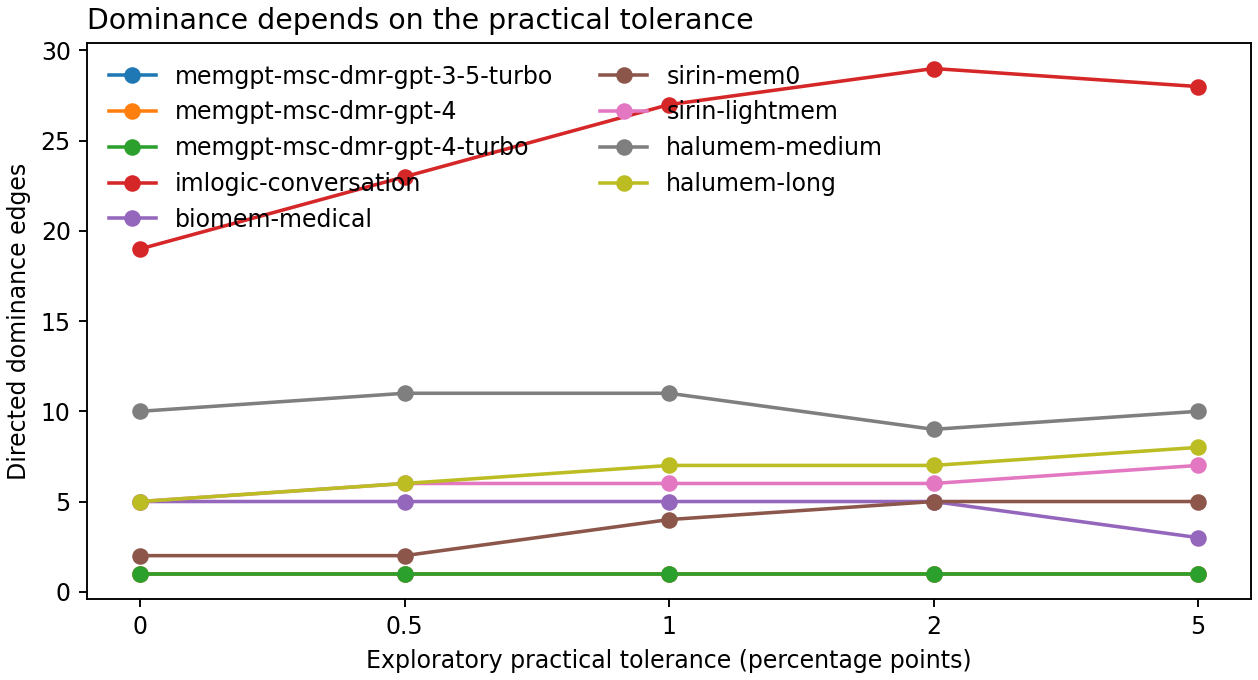

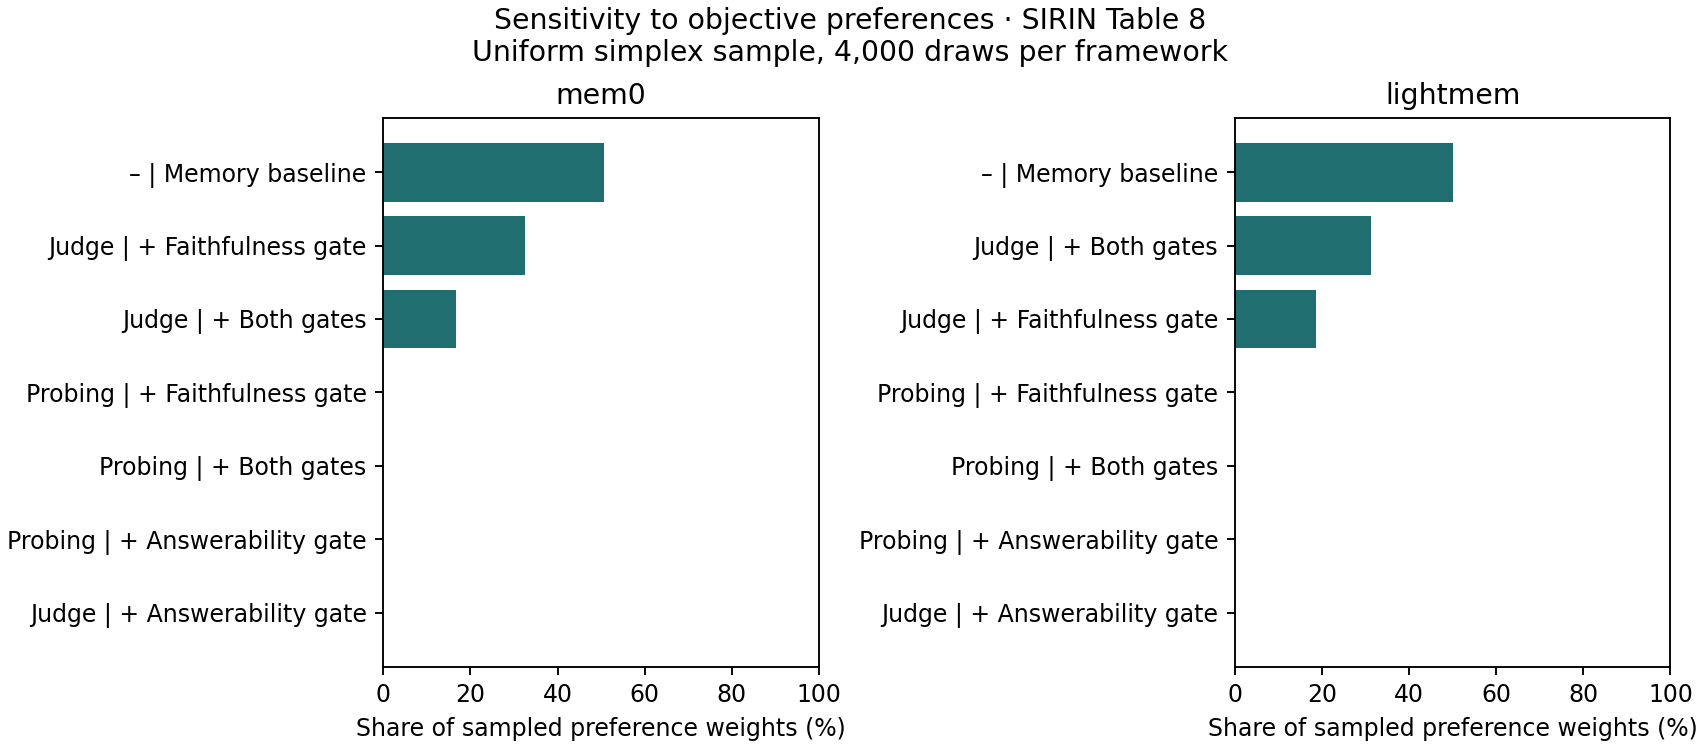

In [9]:
vectors, directions, panel_metadata = load_panels(fronts)
robust_counts = {}
for panel, outcomes in vectors.items():
    edge_sets = [tolerance_edges(outcomes, directions[panel], tolerance) for tolerance in TOLERANCES]
    robust_counts[panel] = len(set.intersection(*edge_sets))
assert sum(robust_counts.values()) == 39
table(("Panel", "Edges retained at every tolerance"), robust_counts.items())
normalization = read(result / "effect_size_sensitivity.csv")
print("Normalization comparisons:", dict(Counter(r["status"] for r in normalization)))
inclusion = read(result / "evidence_selection_sensitivity.csv")
fields([r for r in inclusion if "relaxed" in r["scenario"] or "pooled" in r["scenario"]],
       "panel", "scenario", "status", "reason")
figure(figures / "stage2d_tolerance.png",
       "Within-panel dominance counts across the prespecified exploratory tolerance grid. Changes reflect analytical thresholds and do not represent confidence intervals.")
figure(figures / "stage2d_objective_weights.png",
       "SIRIN preference regions under the fixed percentage utility scale. Shares describe which configuration wins under hypothetical objective weights.")

## 9. Final architecture candidate selection
The decision procedure starts with source eligibility and outcome relevance. It then checks matched directions, competing objectives, threshold sensitivity, uncertainty and coverage before making a scope-specific recommendation. Dependence is tracked at the cohort level. A local finding can nominate a carefully qualified candidate. A general-purpose claim would require aligned independent replication across meaningful workloads and observations of both direct harm and memory utility.

- **MemOS on HaluMem QA** has robust joint point-estimate dominance in both linked splits, although its Long hallucination difference versus Mem0 is only 0.68 points. Conditional extraction diagnostics show weak distractor rejection. Outcome stage and system-specific budgets matter.
- **SIRIN Judge faithfulness gates** on Mem0 and LightMem reduce strict unfaithfulness among served answers while losing 20 points of coverage. On Mem0, the answerability-only Judge gate instead increases conditional unfaithfulness. Both-gates paired intervals support served-accuracy differences only.
- **TRUSTMEM** has a consolidation-specific result, 0.01% versus 0.05% unsupported transitions against Mem-T. Transition counts and paired uncertainty are unavailable. No strict downstream hallucination comparison generalizes that result.
- **RootMem additions** improve the corresponding MemOS, LightMem and EverMemOS bases on the IMLogic forced-choice panel. MemOS + RootMem has the most stable first-front membership across objective omissions among the three. Lower preference-trap rates can come at the expense of overall accuracy, as TACITREE illustrates.
- **BioMem HMRU-R** improves medical updating QA versus A-Mem, with the small edge absorbed at 5 points. HMRU-I improves alignment recall alongside worse alignment QA. HMRU-T weakens temporal and updating QA despite some recall gains.
- **RMM** improves matched-retriever LongMemEval QA and improves MSC next-response METEOR against matched RAG. Effect magnitude depends on retriever and workload. **MemGPT** outperforms its lossy-summary controls in three reader blocks using one set of historical-fact questions. MemGPT was instructed to guess from available memory, while the summary-only control was told to withhold answers when information was insufficient. These are episodic-memory outcomes with no direct hallucination endpoint.

These are scoped decisions. A high score from an unmatched protocol, such as Oracle Agent Memory's LongMemEval result, does not outrank a source-local comparison.

criterion_id,criterion,operation
C1,Identity and eligibility,Use paper-specific version and configuration IDs. Use directly comparable verified original non-excluded pairs for directional claims. Keep conditional and ineligible evidence as context.
C2,Outcome relevance,Judge direct hallucination and strict unfaithfulness separately. Retain denominator and rubric. Classify task-specific diagnostics separately from broad memory-performance proxies.
C3,Local recommendation,Require a favorable matched result on a relevant endpoint alongside review of comparator choice and available competing objectives. Use robustness and reported paired uncertainty when available and record when they are absent.
C4,General-purpose recommendation,Require compatible independent replication across meaningfully distinct workloads and evidence on both direct harm and memory utility. Count each dependent cohort once and keep linked splits nested.
C5,Specialized and trade-off recommendations,Allow specialized hypotheses from a single well-documented protocol or cohort. Preserve negative objectives and reported threshold or weight sensitivity. Coverage loss can limit conditional unfaithfulness benefits.
C6,Underperformance and missingness,Use consistent local disadvantage only within a specified panel or repeated like-for-like comparisons. Report unsupported or unmatched outcomes explicitly and assign no performance value to gaps.
C7,Head-to-head panel selection,Choose direct harm and selective faithfulness panels and a controlled failure-mode protocol for compatible scoring and meaningful interventions independently of winner identity. Include complete eligible competitor sets for the chosen scopes.
C8,No pooled ranking,Do not combine effect sizes across incompatible benchmarks. Count panels and conservative cohort labels as coverage descriptors. Use no numerical evidence-strength score or architecture leaderboard.


candidate_id,decision,n_anchor_panels,n_cohort_labels,limitations
halumem-memos,local hallucination candidate,2,1,Direct QA rubric. Locally robust across the two linked splits. Extraction and updating are separate protocols.
sirin-mem0-faithfulness,specialized selective intervention; trade-off,1,1,Conditional unfaithfulness with lower coverage.
sirin-lightmem-faithfulness,specialized selective intervention; trade-off,1,1,Conditional unfaithfulness with lower coverage.
sirin-mem0-both,specialized selective intervention; trade-off,1,1,Coverage and unfaithfulness can favor other gates.
sirin-lightmem-both,specialized selective intervention; trade-off,1,1,Served accuracy improves over Judge faithfulness with lower coverage.
sirin-simplemem-both,specialized selective intervention; distinct protocol,1,1,Matched served accuracy. Strict unfaithfulness uses the probe training label and remains conditional.
trustmem-consolidation,specialized memory-write candidate,1,1,Direct transition hallucination in Mem-α; no verified matched downstream HaluMem benefit.
memos-rootmem,specialized implicit logic candidate,1,1,Matched addition; forced-choice diagnostic. Preference trap remains a trade-off.
lightmem-rootmem,specialized implicit logic candidate,1,1,Largest matched accuracy gain among the RootMem additions; first-front membership depends on generic traps.
evermemos-rootmem,specialized implicit logic candidate,1,1,Improves over its own base; first-front membership depends on preference traps.


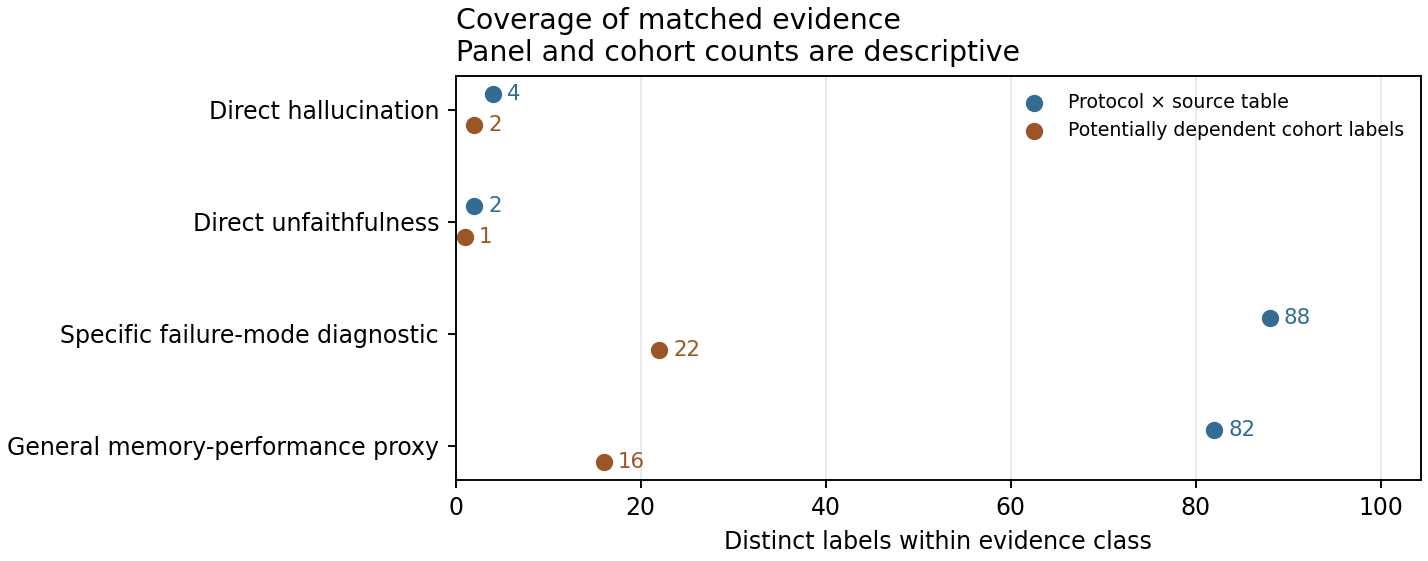

In [10]:
criteria = read(saved / "candidate_selection_criteria.csv")
fields(criteria, "criterion_id", "criterion", "operation")
candidates = read(result / "candidate_shortlist.csv")
fields(candidates, "candidate_id", "decision", "n_anchor_panels", "n_cohort_labels", "limitations")
figure(figures / "stage2e_matched_evidence_coverage.png",
       "Protocol-by-source-table counts and potentially dependent cohort labels for matched evidence classes. The counts show the scarcity of direct evidence without treating labels as independent replications.")

## 10. Direct head-to-head benchmark comparisons
Use the scoped table below to compare configurations under shared conditions. Values are in the original units. The tables use direct point contrasts and rank within each outcome. No rows are pooled across panels.

- **HaluMem QA Table 3, PDF p. 11.** GPT-4o generator and judge. Accuracy, incorrect-or-fabricated answers and omission are reported as percentages of questions. Incomplete and partial answers can count as omission. Retrieval settings vary by system. The 500-token recall cap applies to Memobase. Long Memobase is conditional and excluded from strict comparison.
- **SIRIN Table 8, PDF p. 11.** Separate Mem0 and LightMem panels under Qwen3.5-35B-A3B generation. GPT-5.4-mini is the Judge gate. Claude Sonnet 5 labels strict unfaithfulness, and the served-accuracy scorer endpoint is unspecified. Coverage is $100-\text{abstention percent}$. Accuracy and strict unfaithfulness are conditional on service. Retrospective thresholds and varying served subsets limit deployment inference. The product $P(\mathrm{serve})P(\mathrm{unfaithful}\mid\mathrm{serve})$ estimates an all-query event frequency only when weighting and scorer inclusion refer to the same population.

- **Original LongMemEval-M Tables 3–4, PDF pp. 9–10.** Session values and top-five retrieval in both scopes. Table 3 fixes a GPT-4o reader and GPT-4o-2024-08-06 judge for QA correctness. Table 4 fixes the Stella retriever and measures temporal supporting-evidence recall and rank-discounted NDCG. They reuse an original-question cohort and do not measure hallucination directly.

In [11]:
head = read(result / "head_to_head_benchmark_comparisons.csv")
for panel in dict.fromkeys(r["panel"] for r in head):
    unique = {}
    for row in (r for r in head if r["panel"] == panel):
        for side in ("target", "reference"):
            cell = json.loads(row[side])
            unique[cell["configuration_id"], row["metric"]] = (
                cell["source_label"], row["metric"], cell["score"], row["unit"], row[f"{side}_rank"])
    display(HTML(f"<h4>{escape(panel)}</h4>"))
    table(("Evaluated configuration", "Outcome", "Score", "Unit", "Rank"), unique.values())

Evaluated configuration,Outcome,Score,Unit,Rank
Value = Session | K = summary,Accuracy,0.554,proportion,7
Value = Session | K = V,Accuracy,0.670,proportion,2
Value = Session | K = fact,Accuracy,0.644,proportion,5
Value = Session | K = keyphrase,Accuracy,0.618,proportion,6
Value = Session | K = V + summary,Accuracy,0.658,proportion,4
Value = Session | K = V + fact,Accuracy,0.714,proportion,1
Value = Session | K = V + keyphrase,Accuracy,0.665,proportion,3


Evaluated configuration,Outcome,Score,Unit,Rank
(1) w/ Query Expansion (MT = GPT-4o),Recall@5,0.654,proportion,4
(1) K = V,Recall@5,0.639,proportion,5
(1) w/ Query Expansion (MT = Llama 3.1 8B Instruct),Recall@5,0.624,proportion,6
(2) K = V + fact,Recall@5,0.684,proportion,2
(2) w/ Query Expansion (MT = GPT-4o),Recall@5,0.722,proportion,1
(2) w/ Query Expansion (MT = Llama 3.1 8B Instruct),Recall@5,0.677,proportion,3
(1) w/ Query Expansion (MT = GPT-4o),NDCG@5,0.660,proportion,4
(1) K = V,NDCG@5,0.630,proportion,5
(1) w/ Query Expansion (MT = Llama 3.1 8B Instruct),NDCG@5,0.627,proportion,6
(2) K = V + fact,NDCG@5,0.688,proportion,2


Evaluated configuration,Outcome,Score,Unit,Rank
Medium | Mem0-Graph,Accuracy,54.66,percent,3
Medium | Mem0,Accuracy,53.02,percent,5
Medium | Memobase,Accuracy,35.33,percent,6
Medium | MemOS,Accuracy,67.23,percent,1
Medium | Supermemory,Accuracy,54.07,percent,4
Medium | Zep,Accuracy,55.47,percent,2
Medium | Mem0-Graph,Hallucination rate,19.28,percent,3
Medium | Mem0,Hallucination rate,19.17,percent,2
Medium | Memobase,Hallucination rate,29.97,percent,6
Medium | MemOS,Hallucination rate,15.17,percent,1


Evaluated configuration,Outcome,Score,Unit,Rank
Long | Mem0-Graph,Accuracy,32.44,percent,4
Long | Mem0,Accuracy,28.11,percent,5
Long | MemOS,Accuracy,64.44,percent,1
Long | Supermemory,Accuracy,53.77,percent,2
Long | Zep,Accuracy,50.19,percent,3
Long | Mem0-Graph,Hallucination rate,21.82,percent,3
Long | Mem0,Hallucination rate,17.29,percent,2
Long | MemOS,Hallucination rate,16.61,percent,1
Long | Supermemory,Hallucination rate,22.21,percent,4
Long | Zep,Hallucination rate,22.51,percent,5


Evaluated configuration,Outcome,Score,Unit,Rank
Mem0 | SIRIN Probing | + Answerability gate,Served accuracy,43.5,percent,3
Mem0 | – | Memory baseline,Served accuracy,37.8,percent,7
Mem0 | SIRIN Probing | + Faithfulness gate,Served accuracy,39.8,percent,6
Mem0 | SIRIN Probing | + Both gates,Served accuracy,46.9,percent,2
Mem0 | SIRIN Judge | + Answerability gate,Served accuracy,43.5,percent,3
Mem0 | SIRIN Judge | + Faithfulness gate,Served accuracy,42.8,percent,5
Mem0 | SIRIN Judge | + Both gates,Served accuracy,51.0,percent,1
Mem0 | SIRIN Probing | + Answerability gate,Strict unfaithfulness,36.1,percent,6
Mem0 | – | Memory baseline,Strict unfaithfulness,35.1,percent,5
Mem0 | SIRIN Probing | + Faithfulness gate,Strict unfaithfulness,25.3,percent,2


Evaluated configuration,Outcome,Score,Unit,Rank
LightMem | SIRIN Probing | + Answerability gate,Served accuracy,54.2,percent,5
LightMem | – | Memory baseline,Served accuracy,50.2,percent,6
LightMem | SIRIN Probing | + Faithfulness gate,Served accuracy,50.0,percent,7
LightMem | SIRIN Probing | + Both gates,Served accuracy,55.3,percent,4
LightMem | SIRIN Judge | + Answerability gate,Served accuracy,56.5,percent,2
LightMem | SIRIN Judge | + Faithfulness gate,Served accuracy,56.2,percent,3
LightMem | SIRIN Judge | + Both gates,Served accuracy,64.5,percent,1
LightMem | SIRIN Probing | + Answerability gate,Strict unfaithfulness,32.9,percent,6
LightMem | – | Memory baseline,Strict unfaithfulness,33.1,percent,7
LightMem | SIRIN Probing | + Faithfulness gate,Strict unfaithfulness,26.1,percent,3


Panel,Outcome,A,B,Oriented A vs B,Score scale,Joint outcome
halumem-long,Hallucination rate,Long | MemOS,Long | Mem0,0.68,percent,Long | MemOS dominates
sirin-mem0,Strict unfaithfulness,Mem0 | SIRIN Judge | + Faithfulness gate,Mem0 | – | Memory baseline,11.9,percent,trade-off
sirin-mem0,Answer coverage,Mem0 | SIRIN Judge | + Faithfulness gate,Mem0 | – | Memory baseline,-20.0,percent,trade-off
longmemeval-qa,Accuracy,Value = Session | K = V + fact,Value = Session | K = V,0.044,proportion,
longmemeval-temporal,Recall@5,(2) w/ Query Expansion (MT = GPT-4o),(1) K = V,0.083,proportion,


source_row,metric,score,ci_lower,ci_upper,unit
Mem0 | SIRIN Probing + Both,Paired served accuracy change,+9.1,+5.9,+12.3,percentage_points
Mem0 | SIRIN Judge + Both,Paired served accuracy change,+13.2,+10.1,+16.4,percentage_points
Mem0 | SIRIN Probing | + Answerability gate,Probe minus Judge paired served-accuracy change,,-2.1,2.2,percentage_points
Mem0 | SIRIN Probing | + Both gates,Probe minus Judge paired served-accuracy change,,-7.8,-0.4,percentage_points
LightMem | SIRIN Probing + Both,Paired served accuracy change,+5.1,+1.9,+8.4,percentage_points
LightMem | SIRIN Judge + Both,Paired served accuracy change,+14.3,+11.0,+17.7,percentage_points
LightMem | SIRIN Probing | + Answerability gate,Probe minus Judge paired served-accuracy change,,-4.5,0.0,percentage_points
LightMem | SIRIN Probing | + Both gates,Probe minus Judge paired served-accuracy change,,-13.1,-5.1,percentage_points


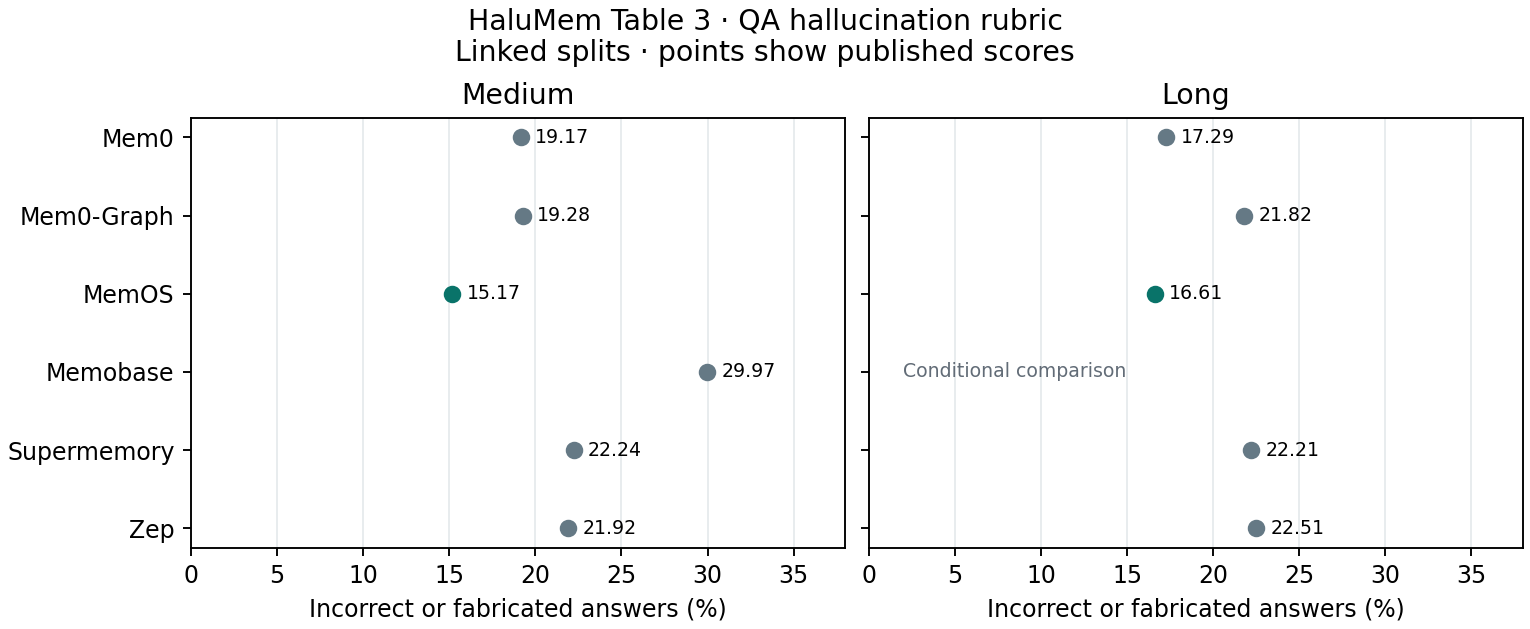

In [12]:
def compare(panel, metric, a, b):
    for row in head:
        if (row["panel"], row["metric"]) != (panel, metric):
            continue
        left, right = (json.loads(row[side]) for side in ("target", "reference"))
        if {left["source_label"], right["source_label"]} != {a, b}:
            continue
        signed = Decimal(row["absolute_difference"]) * (1 if left["source_label"] == a else -1)
        return panel, metric, a, b, signed, row["unit"], row["pareto_relationship"].replace(
            "target dominates", left["source_label"] + " dominates").replace("reference dominates", right["source_label"] + " dominates")
    raise ValueError((panel, metric, a, b))

examples = [
    compare("halumem-long", "Hallucination rate", "Long | MemOS", "Long | Mem0"),
    compare("sirin-mem0", "Strict unfaithfulness", "Mem0 | SIRIN Judge | + Faithfulness gate", "Mem0 | – | Memory baseline"),
    compare("sirin-mem0", "Answer coverage", "Mem0 | SIRIN Judge | + Faithfulness gate", "Mem0 | – | Memory baseline"),
    compare("longmemeval-qa", "Accuracy", "Value = Session | K = V + fact", "Value = Session | K = V"),
    compare("longmemeval-temporal", "Recall@5", "(2) w/ Query Expansion (MT = GPT-4o)", "(1) K = V"),
]
table(("Panel", "Outcome", "A", "B", "Oriented A vs B", "Score scale", "Joint outcome"), examples)
paired = {item["observation_id"]: item for row in head for item in json.loads(row["reported_paired_statistics"] or "[]")}
fields(list(paired.values()), "source_row", "metric", "score", "ci_lower", "ci_upper", "unit")
figure(figures / "stage2e_halumem_head_to_head.png",
       "Published HaluMem QA hallucination-category rates for strict competitors within each split. No paired intervals were reported. The linked splits are dependent.")

For SIRIN, the interval rows retain the publication's orientation. The Mem0 and LightMem Judge both-gates gains versus ungated have published 95% paired cluster-bootstrap intervals of [10.1, 16.4] and [11.0, 17.7] percentage points. No such intervals are assigned here to hallucination, coverage or the LongMemEval retrieval comparisons.

## 11. Unsupported statistical methods
Bradley–Terry models express pairwise win probabilities using latent strengths. For systems $i,j$,
$$
P(i\succ j)=\frac{e^{\theta_i}}{e^{\theta_i}+e^{\theta_j}},
\qquad \operatorname{logit}P(i\succ j)=\theta_i-\theta_j.
$$
Adding a constant to all $\theta_i$ leaves the likelihood invariant, so a reference constraint is required. Even with a connected comparison design on the intended outcome, weak support and separation can prevent reliable maximum likelihood estimates. Penalties or Bayesian priors can stabilize a fit. Differences in endpoints, protocols and configurations can still leave pooled comparisons unidentified. A graph connecting architecture labels through heterogeneous experiments does not guarantee a connected design for the same estimand.

Reliable inference would need matched intervention definitions, outcomes and scorers, paired item-level results or suitable uncertainty, independent replication and explicit modelling of correlations among shared histories and endpoints. Here many nominal pair comparisons are derived from the same outcomes. No aligned independent cross-study replication sufficient for pooled ranking was established. No model is fitted.

## 12. Final conclusions
The strongest Cluster B answer to RQ3 is benchmark- and failure-specific. MemOS is the leading directly matched HaluMem QA candidate. SIRIN warrants prospective evaluation where selective answering is desirable, and TRUSTMEM warrants further consolidation-specific checks. Controlled retrieval, memory updating and implicit logic results identify narrower hypotheses for RMM, MemGPT, BioMem and RootMem.

The evidence supports observed local contrasts within named configurations and defensible sensitivity analyses. Qualifying a candidate for broader use would require prospective aligned replication, coverage-aware event denominators and paired uncertainty. Sparse or incompatible evidence leaves cross-study rankings unidentified rather than establishing that systems perform equally.

In [13]:
scratch.cleanup()
print("Temporary results removed. Saved source datasets and research outputs were used read-only.")

Temporary results removed. Saved source datasets and research outputs were used read-only.
